In [3]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
os.makedirs("results", exist_ok=True)

# ============================================================
# Feature extraction (same MFCC setup as Lab 8)
# ============================================================
RAVDESS_EMOTION_MAP = {
    "01": "neutral", "02": "calm", "03": "happy", "04": "sad",
    "05": "angry", "06": "fearful", "07": "disgust", "08": "surprised"
}


def get_emotion_from_filename(file_name):
    """3rd field of a RAVDESS file name (e.g. 03-01-06-01-02-01-12.wav) is the emotion code."""
    return RAVDESS_EMOTION_MAP.get(file_name.split("-")[2], "unknown")


def extract_mfcc_features(file_path, n_mfcc=40):
    """Returns the mean of each MFCC coefficient over time for one audio clip."""
    import librosa
    audio_signal, sample_rate = librosa.load(file_path, sr=None)
    mfcc_matrix = librosa.feature.mfcc(y=audio_signal, sr=sample_rate, n_mfcc=n_mfcc)
    return np.mean(mfcc_matrix, axis=1)


def build_dataset_from_folder(root_folder, n_mfcc=40):
    """Same MFCC features as before, but extracted in parallel across all CPU cores."""
    from joblib import Parallel, delayed
    wav_paths = []
    for current_dir, _, file_names in os.walk(root_folder):
        for file_name in sorted(file_names):
            if file_name.endswith(".wav"):
                wav_paths.append(os.path.join(current_dir, file_name))

    feature_rows = Parallel(n_jobs=-1, verbose=5)(
        delayed(extract_mfcc_features)(path, n_mfcc) for path in wav_paths
    )
    label_rows = [get_emotion_from_filename(os.path.basename(path)) for path in wav_paths]
    return np.array(feature_rows), np.array(label_rows)


def load_or_build_features(root_folder, cache_file="ravdess_mfcc_features.npz"):
    """Extracts features once and caches them so later runs are instant."""
    if os.path.exists(cache_file):
        cached = np.load(cache_file, allow_pickle=True)
        return cached["X"], cached["y"]
    X, y = build_dataset_from_folder(root_folder)
    np.savez(cache_file, X=X, y=y)
    return X, y


# ============================================================
# Pipeline / model helpers
# ============================================================
def build_pipeline(classifier, use_pca=False):
    """StandardScaler -> (optional PCA keeping 95% variance) -> classifier."""
    steps = [("scaler", StandardScaler())]
    if use_pca:
        steps.append(("pca", PCA(n_components=0.95, random_state=1)))
    steps.append(("clf", classifier))
    return Pipeline(steps)


def evaluate_model(model, X_train, X_test, y_train, y_test):
    """Fits the model and returns (metrics_dict, test_predictions). Macro-averaged metrics."""
    start_time = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - start_time
    train_pred = np.ravel(model.predict(X_train))
    test_pred = np.ravel(model.predict(X_test))
    metrics = {
        "Train Acc": accuracy_score(y_train, train_pred),
        "Test Acc": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, test_pred, average="macro", zero_division=0),
        "F1": f1_score(y_test, test_pred, average="macro", zero_division=0),
        "Fit Time (s)": fit_time,
    }
    return metrics, test_pred


def run_random_search(pipeline, param_distributions, X_train, y_train, n_iter=20, n_splits=3, seed=1):
    """RandomizedSearchCV with stratified CV, optimising macro F1."""
    cv_splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    search = RandomizedSearchCV(pipeline, param_distributions, n_iter=n_iter, scoring="f1_macro",
                                cv=cv_splitter, random_state=seed, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    return search


def get_other_classifiers(seed=1):
    """The extra classifiers for A3, each wrapped with a StandardScaler."""
    return {
        "SVM (RBF)": build_pipeline(SVC(kernel="rbf", C=10, gamma="scale", random_state=seed)),
        "Decision Tree": build_pipeline(DecisionTreeClassifier(random_state=seed)),
        "Random Forest": build_pipeline(RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=-1)),
        "CatBoost": build_pipeline(CatBoostClassifier(iterations=300, learning_rate=0.1, depth=6, verbose=0,
                                                      random_seed=seed, allow_writing_files=False)),
        "AdaBoost": build_pipeline(AdaBoostClassifier(n_estimators=200, random_state=seed)),
        "XGBoost": build_pipeline(XGBClassifier(n_estimators=300, learning_rate=0.1, eval_metric="mlogloss",
                                                random_state=seed, n_jobs=-1)),
        "Naive Bayes": build_pipeline(GaussianNB()),
    }


# ============================================================
# Plot helpers
# ============================================================
def plot_confusion(y_true, y_pred, class_names, title, save_path):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(save_path, dpi=200)
    plt.show()


def plot_metric_bars(results_df, save_path):
    ordered = results_df.sort_values("F1")
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(ordered.index, ordered["F1"], color="steelblue")
    ax.set_xlabel("Macro F1 on test set")
    ax.set_title("Classifier comparison on RAVDESS (MFCC features)")
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    fig.savefig(save_path, dpi=200)
    plt.show()


# ============================================================
# LIME helpers
# ============================================================
def explain_with_lime(explainer, instance, predict_fn, num_features=10, num_samples=5000):
    """Explains one prediction. Returns (explanation, predicted_label, class_probabilities)."""
    probabilities = predict_fn(instance.reshape(1, -1))[0]
    predicted_label = int(np.argmax(probabilities))
    explanation = explainer.explain_instance(instance, predict_fn, num_features=num_features,
                                             labels=[predicted_label], num_samples=num_samples)
    return explanation, predicted_label, probabilities


def aggregate_lime_importance(explainer, X_samples, predict_fn, feature_names, num_features=10, num_samples=2000):
    """Sums |LIME weight| per feature over many test samples -> a global-ish importance ranking."""
    importance = np.zeros(len(feature_names))
    for sample in X_samples:
        explanation, predicted_label, _ = explain_with_lime(explainer, sample, predict_fn,
                                                            num_features, num_samples)
        for feature_index, weight in explanation.as_map()[predicted_label]:
            importance[feature_index] += abs(weight)
    importance = importance / len(X_samples)
    return pd.Series(importance, index=feature_names).sort_values(ascending=False)

In [4]:
# ---- Main program: data loading ----
ravdess_folder_path = "ravdess"   # folder with Actor_01 ... Actor_24 inside "lab 09"
assert os.path.exists(ravdess_folder_path), "Dataset folder not found - fix ravdess_folder_path"

X_all, y_text = load_or_build_features(ravdess_folder_path)   # first run takes a few minutes

label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(y_text)
class_names = list(label_encoder.classes_)
feature_names = ["MFCC_" + str(i + 1) for i in range(X_all.shape[1])]

# same split settings as Lab 8 so results stay comparable
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=1, stratify=y_all
)

print("Total samples :", X_all.shape[0])
print("Features      :", X_all.shape[1])
print("Train / Test  :", X_train.shape[0], "/", X_test.shape[0])
print("\nClass counts:\n", pd.Series(y_text).value_counts().to_string())

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:    3.9s
[Parallel(n_jobs=-1)]: Done  56 tasks      | elapsed:   16.2s
[Parallel(n_jobs=-1)]: Done 146 tasks      | elapsed:   42.0s
[Parallel(n_jobs=-1)]: Done 272 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done 434 tasks      | elapsed:  1.8min
[Parallel(n_jobs=-1)]: Done 632 tasks      | elapsed:  2.4min
[Parallel(n_jobs=-1)]: Done 866 tasks      | elapsed:  3.4min
[Parallel(n_jobs=-1)]: Done 1136 tasks      | elapsed:  4.3min


Total samples : 1439
Features      : 40
Train / Test  : 1151 / 288

Class counts:
 calm         192
sad          192
angry        192
fearful      192
disgust      192
surprised    192
happy        191
neutral       96


[Parallel(n_jobs=-1)]: Done 1439 out of 1439 | elapsed:  5.4min finished


                      Train Acc  Test Acc  Precision  Recall      F1  Fit Time (s)
Perceptron (default)     0.4075    0.3715     0.3605  0.3516  0.3477         0.054
MLP (Lab 8 config)       1.0000    0.7222     0.7212  0.7228  0.7200         0.552

Per-class report - MLP (Lab 8 config):
              precision    recall  f1-score   support

       angry       0.78      0.79      0.78        39
        calm       0.84      0.82      0.83        38
     disgust       0.59      0.63      0.61        38
     fearful       0.74      0.82      0.78        39
       happy       0.69      0.63      0.66        38
     neutral       0.64      0.74      0.68        19
         sad       0.84      0.68      0.75        38
   surprised       0.67      0.67      0.67        39

    accuracy                           0.72       288
   macro avg       0.72      0.72      0.72       288
weighted avg       0.73      0.72      0.72       288



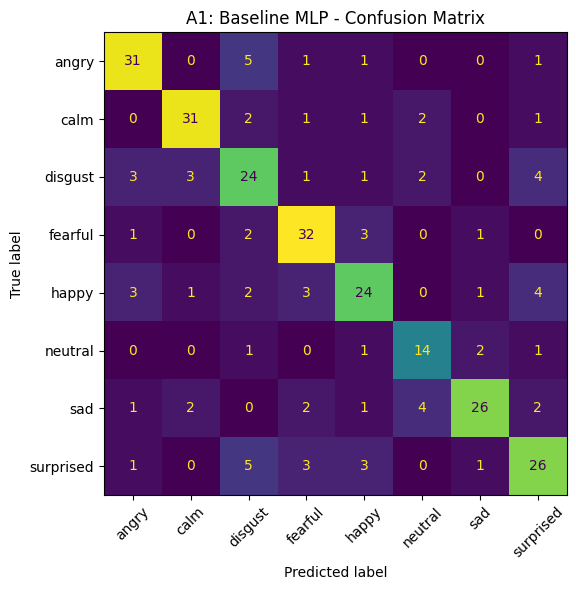

In [5]:
# ---- Main program: A1 ----
baseline_models = {
    "Perceptron (default)": build_pipeline(Perceptron(random_state=1)),
    "MLP (Lab 8 config)": build_pipeline(MLPClassifier(hidden_layer_sizes=(128, 64), activation="relu",
                                                       learning_rate_init=0.001, max_iter=500, random_state=1)),
}

baseline_rows, baseline_preds = {}, {}
for model_name, model in baseline_models.items():
    metrics, predictions = evaluate_model(model, X_train, X_test, y_train, y_test)
    baseline_rows[model_name] = metrics
    baseline_preds[model_name] = predictions

baseline_df = pd.DataFrame(baseline_rows).T.round(4)
print(baseline_df.to_string())
baseline_df.to_csv("results/A1_baseline.csv")

print("\nPer-class report - MLP (Lab 8 config):")
print(classification_report(y_test, baseline_preds["MLP (Lab 8 config)"], target_names=class_names, zero_division=0))

plot_confusion(y_test, baseline_preds["MLP (Lab 8 config)"], class_names,
               "A1: Baseline MLP - Confusion Matrix", "results/A1_confusion_mlp.png")

In [6]:
# ---- Main program: A2 ----
perceptron_param_dist = {
    "clf__alpha": loguniform(1e-6, 1e-1),
    "clf__penalty": [None, "l2", "l1", "elasticnet"],
    "clf__eta0": loguniform(1e-3, 10),
    "clf__tol": loguniform(1e-5, 1e-2),
    "clf__max_iter": [500, 1000, 2000],
    "clf__class_weight": [None, "balanced"],
}

mlp_param_dist = {
    "clf__hidden_layer_sizes": [(64,), (128,), (128, 64), (256, 128), (100, 50, 25)],
    "clf__activation": ["relu", "tanh", "logistic"],
    "clf__alpha": loguniform(1e-5, 1e-1),
    "clf__learning_rate_init": loguniform(1e-4, 1e-2),
    "clf__batch_size": [32, 64, 128, "auto"],
}

perceptron_search = run_random_search(build_pipeline(Perceptron(random_state=1)),
                                      perceptron_param_dist, X_train, y_train, n_iter=30)
mlp_search = run_random_search(build_pipeline(MLPClassifier(max_iter=500, random_state=1)),
                               mlp_param_dist, X_train, y_train, n_iter=20)

for search_name, search in [("Perceptron", perceptron_search), ("MLP", mlp_search)]:
    print("=====", search_name, "=====")
    print("Best params     :", search.best_params_)
    print("Best CV macro-F1:", round(search.best_score_, 4))
    top5 = pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
    print(top5.sort_values("rank_test_score").head(5).to_string(index=False))
    print()

# default vs tuned on the held-out test set
tuned_rows = {}
tuned_preds = {}
for model_name, model in [("Perceptron (default)", baseline_models["Perceptron (default)"]),
                          ("Perceptron (tuned)", perceptron_search.best_estimator_),
                          ("MLP (Lab 8 config)", baseline_models["MLP (Lab 8 config)"]),
                          ("MLP (tuned)", mlp_search.best_estimator_)]:
    metrics, predictions = evaluate_model(model, X_train, X_test, y_train, y_test)
    tuned_rows[model_name] = metrics
    tuned_preds[model_name] = predictions

tuning_df = pd.DataFrame(tuned_rows).T.round(4)
print(tuning_df.to_string())
tuning_df.to_csv("results/A2_tuning_comparison.csv")

best_params_df = pd.DataFrame({
    "Perceptron": {k.replace("clf__", ""): v for k, v in perceptron_search.best_params_.items()},
    "MLP": {k.replace("clf__", ""): v for k, v in mlp_search.best_params_.items()},
})
best_params_df.to_csv("results/A2_best_params.csv")

===== Perceptron =====
Best params     : {'clf__alpha': np.float64(1.4056787147388342e-05), 'clf__class_weight': None, 'clf__eta0': np.float64(0.4806954824961602), 'clf__max_iter': 1000, 'clf__penalty': 'l2', 'clf__tol': np.float64(2.6373077790924614e-05)}
Best CV macro-F1: 0.3557
                                                                                                                                                                                     params  mean_test_score  std_test_score  rank_test_score
        {'clf__alpha': 1.4056787147388342e-05, 'clf__class_weight': None, 'clf__eta0': 0.4806954824961602, 'clf__max_iter': 1000, 'clf__penalty': 'l2', 'clf__tol': 2.6373077790924614e-05}         0.355665        0.038436                1
 {'clf__alpha': 2.9381282022541275e-05, 'clf__class_weight': 'balanced', 'clf__eta0': 0.003005812401328974, 'clf__max_iter': 1000, 'clf__penalty': 'l2', 'clf__tol': 0.0010876936642969395}         0.351520        0.036395                2
    

                      Train Acc  Test Acc  Precision  Recall      F1  Fit Time (s)
SVM (RBF)                0.9965    0.7743     0.7707  0.7717  0.7695        0.0452
MLP (tuned)              1.0000    0.7535     0.7508  0.7588  0.7500        0.8335
MLP (Lab 8 config)       1.0000    0.7222     0.7212  0.7228  0.7200        0.5499
CatBoost                 0.9991    0.6771     0.6953  0.6709  0.6756        3.6902
Random Forest            1.0000    0.6632     0.6869  0.6578  0.6603        0.3046
XGBoost                  1.0000    0.6424     0.6343  0.6281  0.6282        3.7299
Decision Tree            1.0000    0.4097     0.4080  0.4035  0.4017        0.0278
Perceptron (default)     0.4075    0.3715     0.3605  0.3516  0.3477        0.0122
Perceptron (tuned)       0.3771    0.3507     0.3576  0.3343  0.3406        0.0071
Naive Bayes              0.3501    0.3264     0.4121  0.3345  0.3055        0.0022
AdaBoost                 0.4040    0.2986     0.3045  0.2928  0.2862        0.7565


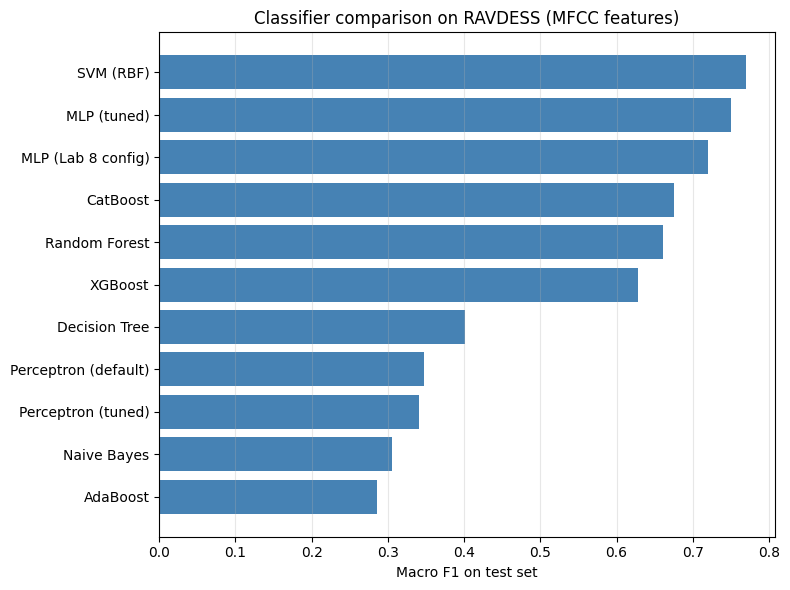


Best model by macro-F1: SVM (RBF)


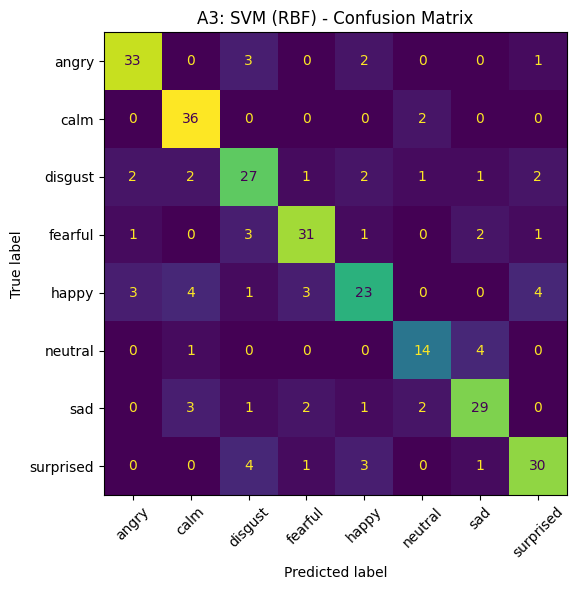

In [7]:
# ---- Main program: A3 ----
all_models = {
    "Perceptron (default)": clone(baseline_models["Perceptron (default)"]),
    "Perceptron (tuned)": clone(perceptron_search.best_estimator_),
    "MLP (Lab 8 config)": clone(baseline_models["MLP (Lab 8 config)"]),
    "MLP (tuned)": clone(mlp_search.best_estimator_),
}
all_models.update(get_other_classifiers())

comparison_rows, comparison_preds = {}, {}
for model_name, model in all_models.items():
    metrics, predictions = evaluate_model(model, X_train, X_test, y_train, y_test)
    comparison_rows[model_name] = metrics
    comparison_preds[model_name] = predictions

results_df = pd.DataFrame(comparison_rows).T.sort_values("F1", ascending=False).round(4)
print(results_df.to_string())
results_df.to_csv("results/A3_classifier_comparison.csv")

plot_metric_bars(results_df, "results/A3_f1_comparison.png")

best_model_name = results_df.index[0]
print("\nBest model by macro-F1:", best_model_name)
plot_confusion(y_test, comparison_preds[best_model_name], class_names,
               "A3: " + best_model_name + " - Confusion Matrix", "results/A3_confusion_best.png")

Pipeline steps: ['scaler', 'pca', 'clf']
5-fold CV macro-F1 (train only): mean = 0.6301  std = 0.0347
PCA components kept: 25 of 40
                          Train Acc  Test Acc  Precision  Recall      F1  Fit Time (s)
MLP (tuned, no PCA)             1.0    0.7535     0.7508  0.7588  0.7500        0.8335
Pipeline: Scaler+PCA+MLP        1.0    0.6875     0.6992  0.6933  0.6921        0.8238


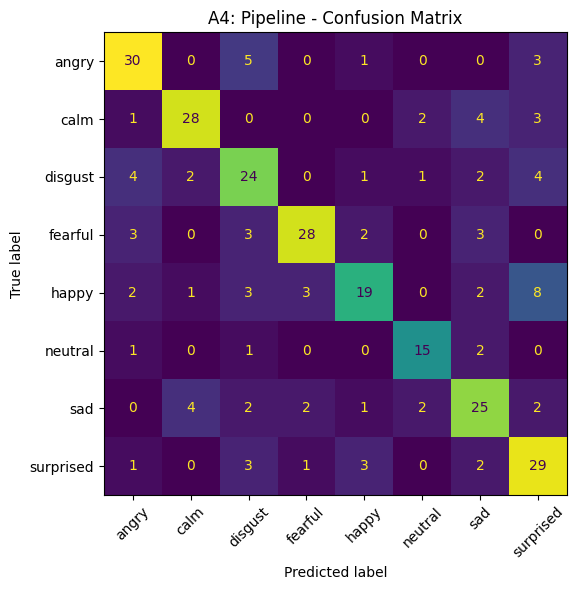

In [8]:
# ---- Main program: A4 ----
# Tuned MLP hyperparameters from A2, now inside a multi-step pipeline: Scaler -> PCA -> MLP
best_mlp_params = {k.replace("clf__", ""): v for k, v in mlp_search.best_params_.items()}
final_pipeline = build_pipeline(MLPClassifier(max_iter=500, random_state=1, **best_mlp_params), use_pca=True)

print("Pipeline steps:", [step_name for step_name, _ in final_pipeline.steps])

# one fit() call runs every step in order; no data leakage in CV because the scaler/PCA are refit per fold
cv_scores = cross_val_score(final_pipeline, X_train, y_train,
                            cv=StratifiedKFold(5, shuffle=True, random_state=1), scoring="f1_macro")
print("5-fold CV macro-F1 (train only): mean =", round(cv_scores.mean(), 4), " std =", round(cv_scores.std(), 4))

pipeline_metrics, pipeline_preds = evaluate_model(final_pipeline, X_train, X_test, y_train, y_test)
print("PCA components kept:", final_pipeline.named_steps["pca"].n_components_, "of", X_train.shape[1])

pipeline_df = pd.DataFrame({
    "MLP (tuned, no PCA)": comparison_rows["MLP (tuned)"],
    "Pipeline: Scaler+PCA+MLP": pipeline_metrics,
}).T.round(4)
print(pipeline_df.to_string())
pipeline_df.to_csv("results/A4_pipeline.csv")

plot_confusion(y_test, pipeline_preds, class_names, "A4: Pipeline - Confusion Matrix",
               "results/A4_confusion_pipeline.png")

===== correct case (test index 0 ) =====
True emotion     : fearful
Predicted emotion: fearful (prob = 0.908 )
Feature condition  LIME weight
 MFCC_19 <= -4.45      -0.1220
  MFCC_8 <= -2.60       0.0755
   MFCC_18 > 1.06       0.0669
 MFCC_20 <= -4.02      -0.0506
 MFCC_30 <= -1.86       0.0494
 MFCC_25 <= -3.77      -0.0463
 MFCC_11 <= -6.39      -0.0442
 MFCC_21 <= -3.69       0.0375
 MFCC_17 <= -4.48      -0.0298
   MFCC_37 > 1.65      -0.0285


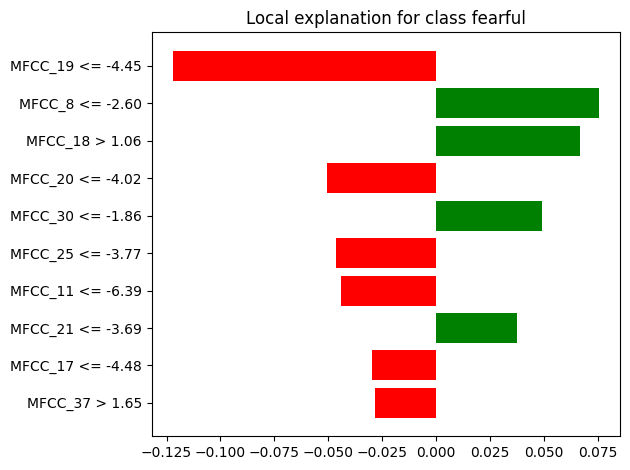


===== misclassified case (test index 2 ) =====
True emotion     : fearful
Predicted emotion: angry (prob = 1.0 )
    Feature condition  LIME weight
     MFCC_1 > -551.91       0.2056
     MFCC_3 <= -12.13       0.0956
      MFCC_14 > -0.86       0.0860
       MFCC_34 > 1.72       0.0691
       MFCC_19 > 1.18      -0.0564
       MFCC_30 > 0.96      -0.0543
       MFCC_28 > 0.96       0.0519
       MFCC_35 > 1.68       0.0447
       MFCC_33 > 0.95      -0.0433
2.85 < MFCC_6 <= 8.61       0.0322


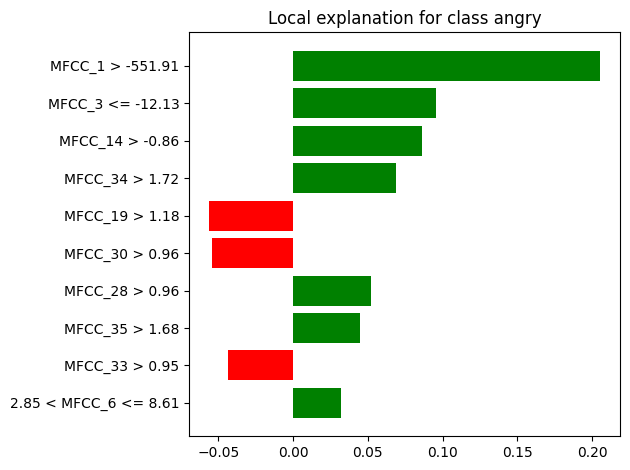


Top 10 features by mean |LIME weight| over 50 test samples:
MFCC_1     0.0747
MFCC_8     0.0417
MFCC_9     0.0339
MFCC_3     0.0339
MFCC_7     0.0295
MFCC_19    0.0239
MFCC_5     0.0230
MFCC_13    0.0221
MFCC_15    0.0215
MFCC_2     0.0210


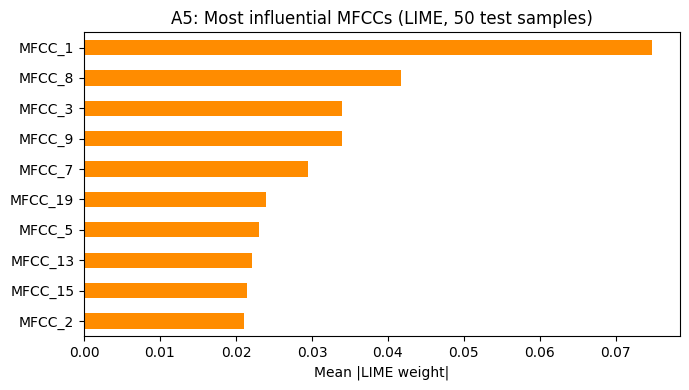

In [9]:
# ---- Main program: A5 ----
from lime.lime_tabular import LimeTabularExplainer

# LIME perturbs the RAW MFCC features and calls the whole pipeline's predict_proba,
# so scaling + PCA + MLP are all explained together as one black box.
lime_explainer = LimeTabularExplainer(
    X_train, feature_names=feature_names, class_names=class_names,
    mode="classification", discretize_continuous=True, random_state=1
)

correct_indices = np.where(pipeline_preds == y_test)[0]
wrong_indices = np.where(pipeline_preds != y_test)[0]
chosen_cases = [("correct", correct_indices[0])]
if len(wrong_indices) > 0:
    chosen_cases.append(("misclassified", wrong_indices[0]))

for case_tag, test_index in chosen_cases:
    explanation, predicted_label, probabilities = explain_with_lime(
        lime_explainer, X_test[test_index], final_pipeline.predict_proba
    )
    print("=====", case_tag, "case (test index", test_index, ") =====")
    print("True emotion     :", class_names[y_test[test_index]])
    print("Predicted emotion:", class_names[predicted_label], "(prob =", round(probabilities[predicted_label], 3), ")")

    lime_table = pd.DataFrame(explanation.as_list(label=predicted_label), columns=["Feature condition", "LIME weight"])
    lime_table["LIME weight"] = lime_table["LIME weight"].round(4)
    print(lime_table.to_string(index=False))
    lime_table.to_csv("results/A5_lime_" + case_tag + ".csv", index=False)

    figure = explanation.as_pyplot_figure(label=predicted_label)
    figure.tight_layout()
    figure.savefig("results/A5_lime_" + case_tag + ".png", dpi=200)
    plt.show()
    explanation.save_to_file("results/A5_lime_" + case_tag + ".html")
    print()

# average LIME importance over 50 random test samples -> which MFCCs matter most overall
rng = np.random.RandomState(1)
sample_indices = rng.choice(len(X_test), size=min(50, len(X_test)), replace=False)
lime_importance = aggregate_lime_importance(lime_explainer, X_test[sample_indices],
                                            final_pipeline.predict_proba, feature_names)
top_lime_features = lime_importance.head(10).round(4)
print("Top 10 features by mean |LIME weight| over 50 test samples:")
print(top_lime_features.to_string())
top_lime_features.to_csv("results/A5_lime_global_top10.csv", header=["Mean |LIME weight|"])

plt.figure(figsize=(7, 4))
top_lime_features.sort_values().plot(kind="barh", color="darkorange")
plt.xlabel("Mean |LIME weight|")
plt.title("A5: Most influential MFCCs (LIME, 50 test samples)")
plt.tight_layout()
plt.savefig("results/A5_lime_global.png", dpi=200)
plt.show()

In [10]:
# ---- Run this last, then copy the whole output ----
for title, csv_path in [("A1 baseline", "results/A1_baseline.csv"),
                        ("A2 default vs tuned", "results/A2_tuning_comparison.csv"),
                        ("A2 best params", "results/A2_best_params.csv"),
                        ("A3 comparison", "results/A3_classifier_comparison.csv"),
                        ("A4 pipeline", "results/A4_pipeline.csv"),
                        ("A5 LIME correct", "results/A5_lime_correct.csv"),
                        ("A5 LIME misclassified", "results/A5_lime_misclassified.csv"),
                        ("A5 LIME global", "results/A5_lime_global_top10.csv")]:
    if os.path.exists(csv_path):
        print("#####", title)
        print(pd.read_csv(csv_path).to_string(index=False))
        print()

##### A1 baseline
          Unnamed: 0  Train Acc  Test Acc  Precision  Recall     F1  Fit Time (s)
Perceptron (default)     0.4075    0.3715     0.3605  0.3516 0.3477         0.054
  MLP (Lab 8 config)     1.0000    0.7222     0.7212  0.7228 0.7200         0.552

##### A2 default vs tuned
          Unnamed: 0  Train Acc  Test Acc  Precision  Recall     F1  Fit Time (s)
Perceptron (default)     0.4075    0.3715     0.3605  0.3516 0.3477        0.0101
  Perceptron (tuned)     0.3771    0.3507     0.3576  0.3343 0.3406        0.0058
  MLP (Lab 8 config)     1.0000    0.7222     0.7212  0.7228 0.7200        0.5559
         MLP (tuned)     1.0000    0.7535     0.7508  0.7588 0.7500        0.8554

##### A2 best params
        Unnamed: 0             Perceptron                   MLP
             alpha 1.4056787147388342e-05  0.013591202736469968
      class_weight                    NaN                   NaN
              eta0     0.4806954824961602                   NaN
          max_iter   